# Bank Customer Churn Segmentation & Retention Prioritization

**Individual Data Analytics / Data Mining Portfolio Project**

This project combines exploratory analysis, business KPIs, churn-aware feature selection, customer segmentation, clustering benchmarks, and an explainable fuzzy decision system.

## Business objective
The goal is not only to predict whether a customer may churn. The project creates interpretable customer segments and converts segment risk plus customer behavior into an actionable **retention priority score**.

## Pipeline
1. Data quality audit and EDA
2. Business KPI analysis
3. Reproducible preprocessing
4. Genetic Algorithm (GA) for **churn-aware feature selection**
5. Dependency-free K-Medoids customer segmentation
6. Hierarchical clustering benchmark
7. Explainable fuzzy retention-priority system
8. End-to-end scoring for new customers
9. Portfolio-ready exports (tables and charts)

> Methodology note: the GA uses the churn label to select business-relevant features. Therefore, the resulting clusters are **churn-informed segments**, not purely unsupervised “natural” clusters. Cluster quality is still evaluated independently with silhouette score and cluster-balance checks.

## 1. Setup and reproducibility

In [1]:
from pathlib import Path
import math
import random
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import AgglomerativeClustering
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import pairwise_distances, silhouette_score
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.preprocessing import RobustScaler
from scipy.cluster.hierarchy import dendrogram, linkage

warnings.filterwarnings('ignore')

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

PROJECT_DIR = Path.cwd()
DATA_PATH = PROJECT_DIR / 'bank_customer_churn.csv'
OUTPUT_DIR = PROJECT_DIR / 'outputs'
CHART_DIR = OUTPUT_DIR / 'charts'
OUTPUT_DIR.mkdir(exist_ok=True)
CHART_DIR.mkdir(parents=True, exist_ok=True)

sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', 30)

print('Project directory:', PROJECT_DIR)
print('Data file:', DATA_PATH)

Project directory: C:\Users\LOQ\Desktop\Bank_Customer_Churn_Portfolio_GitHub_Ready\bank-customer-churn-analysis
Data file: C:\Users\LOQ\Desktop\Bank_Customer_Churn_Portfolio_GitHub_Ready\bank-customer-churn-analysis\bank_customer_churn.csv


## 2. Load and audit the dataset

In [2]:
EXPECTED_COLUMNS = [
    'customer_id', 'credit_score', 'country', 'gender', 'age', 'tenure',
    'balance', 'products_number', 'credit_card', 'active_member',
    'estimated_salary', 'churn'
]

df_raw = pd.read_csv(DATA_PATH)
missing_columns = sorted(set(EXPECTED_COLUMNS) - set(df_raw.columns))
extra_columns = sorted(set(df_raw.columns) - set(EXPECTED_COLUMNS))

if missing_columns:
    raise ValueError(f'Missing expected columns: {missing_columns}')

print(f'Rows: {len(df_raw):,}')
print(f'Columns: {df_raw.shape[1]}')
print(f'Duplicated rows: {df_raw.duplicated().sum():,}')
print(f'Missing values: {int(df_raw.isna().sum().sum()):,}')
print('Extra columns:', extra_columns if extra_columns else 'None')

df_raw.head()

Rows: 10,000
Columns: 12
Duplicated rows: 0
Missing values: 0
Extra columns: None


,customer_id,credit_score,country,gender,age,tenure,balance,products_number,credit_card,active_member,estimated_salary,churn
0,15634602,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,15647311,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,15619304,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,15701354,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,15737888,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [3]:
# Conservative cleaning: remove exact duplicates and impute only if needed.
df = df_raw.drop_duplicates().copy()

numeric_columns = [
    'credit_score', 'age', 'tenure', 'balance', 'products_number',
    'credit_card', 'active_member', 'estimated_salary', 'churn'
]
categorical_columns = ['country', 'gender']

numeric_fill_values = df[numeric_columns].median().to_dict()
categorical_fill_values = {
    col: df[col].mode(dropna=True).iloc[0] for col in categorical_columns
}

for col, value in numeric_fill_values.items():
    df[col] = df[col].fillna(value)
for col, value in categorical_fill_values.items():
    df[col] = df[col].fillna(value)

# Basic domain validation.
if not df['churn'].isin([0, 1]).all():
    raise ValueError('churn must contain only 0/1 values.')
if not df['active_member'].isin([0, 1]).all():
    raise ValueError('active_member must contain only 0/1 values.')
if not df['credit_card'].isin([0, 1]).all():
    raise ValueError('credit_card must contain only 0/1 values.')

print('Cleaned shape:', df.shape)
print('Remaining missing values:', int(df.isna().sum().sum()))

Cleaned shape: (10000, 12)
Remaining missing values: 0


### Outlier audit

Extreme values can be legitimate bank customers, especially for age, balance, and salary. Instead of deleting or arbitrarily clipping them, this project **reports IQR outliers** and later uses `RobustScaler`, which reduces the influence of extreme values while preserving every customer record.

In [4]:
outlier_rows = []
continuous_audit_cols = [
    'credit_score', 'age', 'tenure', 'balance', 'products_number', 'estimated_salary'
]
for col in continuous_audit_cols:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    count = int(((df[col] < lower) | (df[col] > upper)).sum())
    outlier_rows.append([col, lower, upper, count])

outlier_summary = pd.DataFrame(
    outlier_rows,
    columns=['feature', 'iqr_lower_bound', 'iqr_upper_bound', 'outlier_count']
)
outlier_summary.to_csv(OUTPUT_DIR / 'outlier_audit.csv', index=False)
outlier_summary

,feature,iqr_lower_bound,iqr_upper_bound,outlier_count
0,credit_score,383.00000,919.00000,15
1,age,14.00000,62.00000,359
2,tenure,-3.00000,13.00000,0
3,balance,-191466.36000,319110.60000,0
4,products_number,-0.50000,3.50000,60
5,estimated_salary,-96577.09625,296967.45375,0


## 3. Exploratory Data Analysis and business KPIs

In [5]:
# Portfolio-friendly KPI summary.
business_kpis = pd.DataFrame({
    'metric': [
        'Customers', 'Overall churn rate', 'Active member rate',
        'Average age', 'Average balance', 'Average credit score',
        'Average products per customer'
    ],
    'value': [
        len(df), df['churn'].mean(), df['active_member'].mean(),
        df['age'].mean(), df['balance'].mean(), df['credit_score'].mean(),
        df['products_number'].mean()
    ]
})
business_kpis.to_csv(OUTPUT_DIR / 'business_kpis.csv', index=False)
business_kpis

,metric,value
0,Customers,10000.000000
1,Overall churn rate,0.203700
2,Active member rate,0.515100
3,Average age,38.921800
4,Average balance,76485.889288
5,Average credit score,650.528800
6,Average products per customer,1.530200


In [6]:
churn_by_country = (
    df.groupby('country')['churn']
      .agg(customers='size', churn_rate='mean')
      .sort_values('churn_rate', ascending=False)
      .reset_index()
)
churn_by_activity = (
    df.groupby('active_member')['churn']
      .agg(customers='size', churn_rate='mean')
      .reset_index()
)
churn_by_products = (
    df.groupby('products_number')['churn']
      .agg(customers='size', churn_rate='mean')
      .reset_index()
)

churn_by_country.to_csv(OUTPUT_DIR / 'churn_by_country.csv', index=False)
churn_by_activity.to_csv(OUTPUT_DIR / 'churn_by_activity.csv', index=False)
churn_by_products.to_csv(OUTPUT_DIR / 'churn_by_products.csv', index=False)

print('Churn by country')
display(churn_by_country)
print('\nChurn by activity status')
display(churn_by_activity)
print('\nChurn by number of products')
display(churn_by_products)

Churn by country


,country,customers,churn_rate
0,Germany,2509,0.324432
1,Spain,2477,0.166734
2,France,5014,0.161548



Churn by activity status


,active_member,customers,churn_rate
0,0,4849,0.268509
1,1,5151,0.142691



Churn by number of products


,products_number,customers,churn_rate
0,1,5084,0.277144
1,2,4590,0.075817
2,3,266,0.827068
3,4,60,1.000000


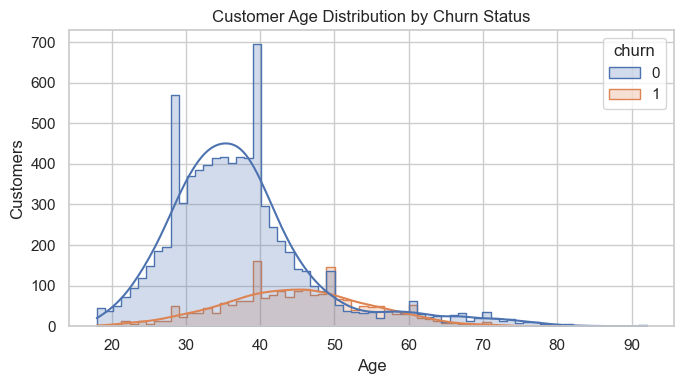

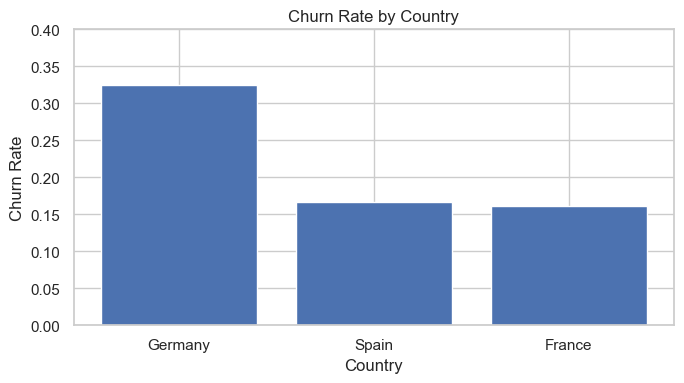

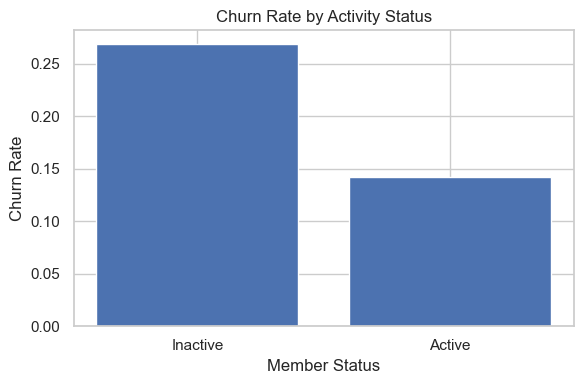

In [7]:
def save_and_show(filename):
    plt.tight_layout()
    plt.savefig(CHART_DIR / filename, dpi=180, bbox_inches='tight')
    plt.show()
    plt.close()

plt.figure(figsize=(7, 4))
sns.histplot(data=df, x='age', hue='churn', kde=True, element='step')
plt.title('Customer Age Distribution by Churn Status')
plt.xlabel('Age')
plt.ylabel('Customers')
save_and_show('age_distribution_by_churn.png')

plt.figure(figsize=(7, 4))
plt.bar(churn_by_country['country'], churn_by_country['churn_rate'])
plt.title('Churn Rate by Country')
plt.xlabel('Country')
plt.ylabel('Churn Rate')
plt.ylim(0, max(0.4, churn_by_country['churn_rate'].max() * 1.15))
save_and_show('churn_rate_by_country.png')

activity_plot = churn_by_activity.copy()
activity_plot['member_status'] = activity_plot['active_member'].map({0: 'Inactive', 1: 'Active'})
plt.figure(figsize=(6, 4))
plt.bar(activity_plot['member_status'], activity_plot['churn_rate'])
plt.title('Churn Rate by Activity Status')
plt.xlabel('Member Status')
plt.ylabel('Churn Rate')
save_and_show('churn_rate_by_activity.png')

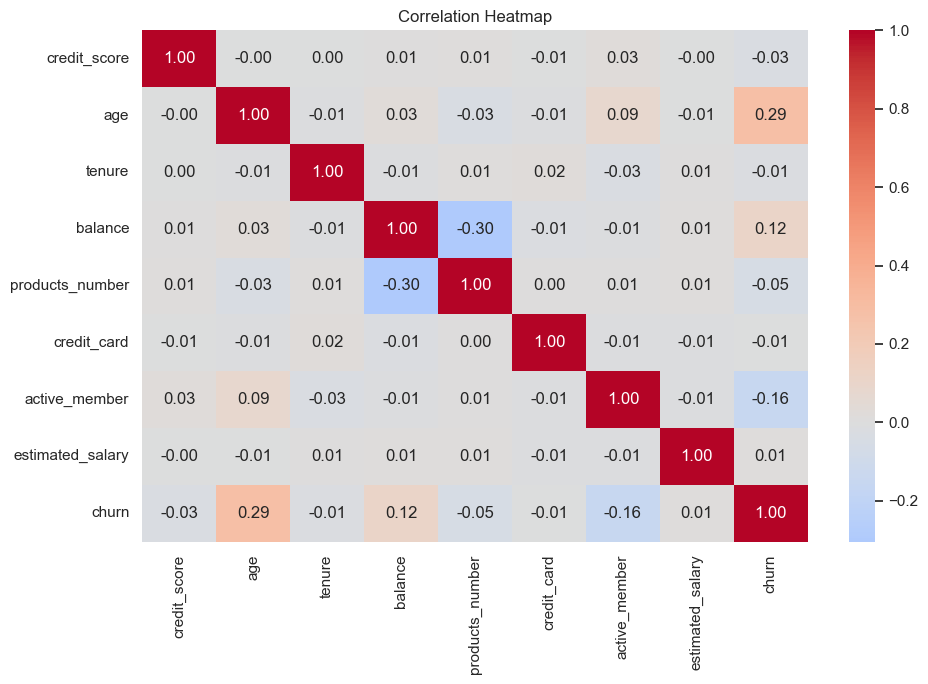

In [8]:
numeric_corr_cols = [
    'credit_score', 'age', 'tenure', 'balance', 'products_number',
    'credit_card', 'active_member', 'estimated_salary', 'churn'
]
plt.figure(figsize=(10, 7))
sns.heatmap(df[numeric_corr_cols].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlation Heatmap')
save_and_show('correlation_heatmap.png')

### EDA takeaways
The following observations are descriptive, not causal conclusions.

In [9]:
overall_churn = df['churn'].mean()
country_high = churn_by_country.iloc[0]
inactive_rate = churn_by_activity.loc[churn_by_activity['active_member'] == 0, 'churn_rate'].iloc[0]
active_rate = churn_by_activity.loc[churn_by_activity['active_member'] == 1, 'churn_rate'].iloc[0]

eda_insights = [
    f'Overall churn rate is {overall_churn:.1%}.',
    f"{country_high['country']} has the highest observed country churn rate at {country_high['churn_rate']:.1%}.",
    f'Inactive customers churn at {inactive_rate:.1%} versus {active_rate:.1%} for active customers.',
    'Customer activity is one of the strongest actionable behavioral signals in the dataset.'
]
for insight in eda_insights:
    print('-', insight)

- Overall churn rate is 20.4%.
- Germany has the highest observed country churn rate at 32.4%.
- Inactive customers churn at 26.9% versus 14.3% for active customers.
- Customer activity is one of the strongest actionable behavioral signals in the dataset.


## 4. Reproducible preprocessing

- Continuous variables use `RobustScaler` so extreme values do not dominate distance calculations.
- Gender is encoded as a binary feature.
- Country is one-hot encoded because country categories do not have an ordinal distance.
- Binary account indicators are kept as 0/1.
- The same fitted transformations are reused for new customer records.

In [10]:
CONTINUOUS_FEATURES = [
    'credit_score', 'age', 'tenure', 'balance', 'products_number', 'estimated_salary'
]
BINARY_FEATURES = ['credit_card', 'active_member']
SOURCE_FEATURES = [
    'credit_score', 'country', 'gender', 'age', 'tenure', 'balance',
    'products_number', 'credit_card', 'active_member', 'estimated_salary'
]
COUNTRY_LEVELS = sorted(df['country'].astype(str).unique().tolist())

continuous_scaler = RobustScaler()
continuous_scaler.fit(df[CONTINUOUS_FEATURES])


def transform_customers(raw_frame: pd.DataFrame) -> pd.DataFrame:
    frame = raw_frame.copy()

    # Apply training-time fallback values.
    for col in CONTINUOUS_FEATURES + BINARY_FEATURES:
        if col not in frame.columns:
            frame[col] = numeric_fill_values.get(col, 0)
        frame[col] = pd.to_numeric(frame[col], errors='coerce').fillna(numeric_fill_values.get(col, 0))

    if 'gender' not in frame.columns:
        frame['gender'] = categorical_fill_values['gender']
    frame['gender'] = frame['gender'].fillna(categorical_fill_values['gender']).astype(str)

    if 'country' not in frame.columns:
        frame['country'] = categorical_fill_values['country']
    frame['country'] = frame['country'].fillna(categorical_fill_values['country']).astype(str)

    transformed = pd.DataFrame(index=frame.index)
    transformed[CONTINUOUS_FEATURES] = continuous_scaler.transform(frame[CONTINUOUS_FEATURES])
    transformed['gender'] = frame['gender'].map({'Female': 0.0, 'Male': 1.0}).fillna(0.5)
    transformed['credit_card'] = frame['credit_card'].clip(0, 1).astype(float)
    transformed['active_member'] = frame['active_member'].clip(0, 1).astype(float)

    for country in COUNTRY_LEVELS:
        transformed[f'country_{country}'] = (frame['country'] == country).astype(float)

    return transformed

X_transformed = transform_customers(df[SOURCE_FEATURES])
y = df['churn'].astype(int).to_numpy()

FEATURE_GROUP_COLUMNS = {
    'credit_score': ['credit_score'],
    'country': [f'country_{country}' for country in COUNTRY_LEVELS],
    'gender': ['gender'],
    'age': ['age'],
    'tenure': ['tenure'],
    'balance': ['balance'],
    'products_number': ['products_number'],
    'credit_card': ['credit_card'],
    'active_member': ['active_member'],
    'estimated_salary': ['estimated_salary']
}

print('Transformed shape:', X_transformed.shape)
X_transformed.head()

Transformed shape: (10000, 12)


,credit_score,age,tenure,balance,products_number,estimated_salary,gender,credit_card,active_member,country_France,country_Germany,country_Spain
0,-0.246269,0.416667,-0.75,-0.761480,0.0,0.011739,0.0,1.0,1.0,1.0,0.0,0.0
1,-0.328358,0.333333,-1.00,-0.104906,0.0,0.125512,0.0,0.0,1.0,0.0,0.0,1.0
2,-1.119403,0.416667,0.75,0.489346,2.0,0.139630,0.0,1.0,0.0,1.0,0.0,0.0
3,0.350746,0.166667,-1.00,-0.761480,1.0,-0.064717,0.0,0.0,0.0,1.0,0.0,0.0
4,1.477612,0.500000,-0.75,0.221806,0.0,-0.214561,0.0,1.0,1.0,0.0,0.0,1.0


## 5. Genetic Algorithm - churn-aware feature selection

The GA chooses a compact subset of **source features** using cross-validated F1 from a balanced Random Forest as the fitness signal. This makes the later segmentation intentionally business-oriented toward churn-relevant behavior.

To prevent the GA from selecting either too few or nearly all features, chromosomes are repaired to keep **3 to 6 source features**. A small size penalty favors compact subsets when predictive quality is similar.

In [11]:
from sklearn.model_selection import StratifiedKFold

GA_SAMPLE_SIZE = min(1500, len(df))
POPULATION_SIZE = 10
GENERATIONS = 10
MUTATION_PROBABILITY = 0.15
MIN_FEATURES = 3
MAX_FEATURES = 6

rng = np.random.default_rng(SEED)
ga_indices = rng.choice(len(df), size=GA_SAMPLE_SIZE, replace=False)
X_ga = X_transformed.iloc[ga_indices].reset_index(drop=True)
y_ga = y[ga_indices]

source_feature_names = list(FEATURE_GROUP_COLUMNS)
num_source_features = len(source_feature_names)
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
fitness_cache = {}


def repair_chromosome(chromosome):
    chromosome = chromosome.copy()
    selected = [i for i, bit in enumerate(chromosome) if bit]

    while len(selected) < MIN_FEATURES:
        choices = [i for i, bit in enumerate(chromosome) if not bit]
        idx = random.choice(choices)
        chromosome[idx] = 1
        selected.append(idx)

    while len(selected) > MAX_FEATURES:
        idx = random.choice(selected)
        chromosome[idx] = 0
        selected.remove(idx)

    return chromosome


def selected_source_features(chromosome):
    return [name for i, name in enumerate(source_feature_names) if chromosome[i] == 1]


def transformed_columns_for_sources(source_names):
    return [column for source in source_names for column in FEATURE_GROUP_COLUMNS[source]]


def raw_f1_for_sources(source_names):
    columns = transformed_columns_for_sources(source_names)
    model = RandomForestClassifier(
        n_estimators=80,
        max_depth=6,
        class_weight='balanced',
        random_state=SEED,
        n_jobs=-1
    )
    return cross_val_score(
        model,
        X_ga[columns].to_numpy(),
        y_ga,
        cv=cv,
        scoring='f1',
        n_jobs=-1
    ).mean()


def ga_fitness(chromosome):
    key = tuple(chromosome)
    if key in fitness_cache:
        return fitness_cache[key]

    source_names = selected_source_features(chromosome)
    score = raw_f1_for_sources(source_names)
    size_penalty = 0.002 * max(0, len(source_names) - MIN_FEATURES)
    fitness_cache[key] = score - size_penalty
    return fitness_cache[key]


def create_individual():
    return repair_chromosome([random.randint(0, 1) for _ in range(num_source_features)])


def tournament_select(population):
    tournament = random.sample(population, 3)
    return max(tournament, key=ga_fitness).copy()


def crossover(parent1, parent2):
    point = random.randint(1, num_source_features - 1)
    return repair_chromosome(parent1[:point] + parent2[point:])


def mutate(individual):
    child = individual.copy()
    for i in range(num_source_features):
        if random.random() < MUTATION_PROBABILITY:
            child[i] = 1 - child[i]
    return repair_chromosome(child)


def run_genetic_algorithm():
    population = [create_individual() for _ in range(POPULATION_SIZE)]
    best_chromosome = None
    best_fitness = -np.inf
    history = []

    for generation in range(GENERATIONS):
        population = sorted(population, key=ga_fitness, reverse=True)
        generation_best = population[0]
        generation_fitness = ga_fitness(generation_best)

        if generation_fitness > best_fitness:
            best_chromosome = generation_best.copy()
            best_fitness = generation_fitness

        history.append(best_fitness)
        print(
            f'Generation {generation + 1:02d} | '
            f'fitness={best_fitness:.4f} | '
            f'features={selected_source_features(best_chromosome)}'
        )

        # Elitism: keep the best two chromosomes.
        next_population = [population[0].copy(), population[1].copy()]
        while len(next_population) < POPULATION_SIZE:
            child = crossover(tournament_select(population), tournament_select(population))
            next_population.append(mutate(child))
        population = next_population

    return best_chromosome, best_fitness, history

best_chromosome, best_ga_fitness, ga_history = run_genetic_algorithm()
selected_features = selected_source_features(best_chromosome)
selected_transformed_columns = transformed_columns_for_sources(selected_features)

selected_f1 = raw_f1_for_sources(selected_features)
all_features_f1 = raw_f1_for_sources(source_feature_names)

print('\nSelected source features:', selected_features)
print(f'Cross-validated F1 - selected subset: {selected_f1:.4f}')
print(f'Cross-validated F1 - all features:     {all_features_f1:.4f}')

Generation 01 | fitness=0.5235 | features=['credit_score', 'age', 'tenure', 'balance', 'products_number', 'estimated_salary']
Generation 02 | fitness=0.5482 | features=['age', 'tenure', 'balance', 'products_number']
Generation 03 | fitness=0.5759 | features=['credit_score', 'age', 'tenure', 'balance', 'products_number', 'active_member']
Generation 04 | fitness=0.5762 | features=['age', 'tenure', 'balance', 'products_number', 'active_member']
Generation 05 | fitness=0.5762 | features=['age', 'tenure', 'balance', 'products_number', 'active_member']
Generation 06 | fitness=0.5762 | features=['age', 'tenure', 'balance', 'products_number', 'active_member']
Generation 07 | fitness=0.5783 | features=['age', 'tenure', 'balance', 'products_number', 'active_member', 'estimated_salary']
Generation 08 | fitness=0.5783 | features=['age', 'tenure', 'balance', 'products_number', 'active_member', 'estimated_salary']
Generation 09 | fitness=0.5783 | features=['age', 'tenure', 'balance', 'products_numbe

Generation 02 | fitness=0.5482 | features=['age', 'tenure', 'balance', 'products_number']


Generation 03 | fitness=0.5759 | features=['credit_score', 'age', 'tenure', 'balance', 'products_number', 'active_member']


Generation 04 | fitness=0.5762 | features=['age', 'tenure', 'balance', 'products_number', 'active_member']


Generation 05 | fitness=0.5762 | features=['age', 'tenure', 'balance', 'products_number', 'active_member']


...

Generation 07 | fitness=0.5783 | features=['age', 'tenure', 'balance', 'products_number', 'active_member', 'estimated_salary']


Generation 08 | fitness=0.5783 | features=['age', 'tenure', 'balance', 'products_number', 'active_member', 'estimated_salary']


Generation 09 | fitness=0.5783 | features=['age', 'tenure', 'balance', 'products_number', 'active_member', 'estimated_salary']


Generation 10 | fitness=0.5783 | features=['age', 'tenure', 'balance', 'products_number', 'active_member', 'estimated_salary']



Selected source features: ['age', 'tenure', 'balance', 'products_number', 'active_member', 'estimated_salary']
Cross-validated F1 - selected subset: 0.5843
Cross-validated F1 - all features:     0.5628


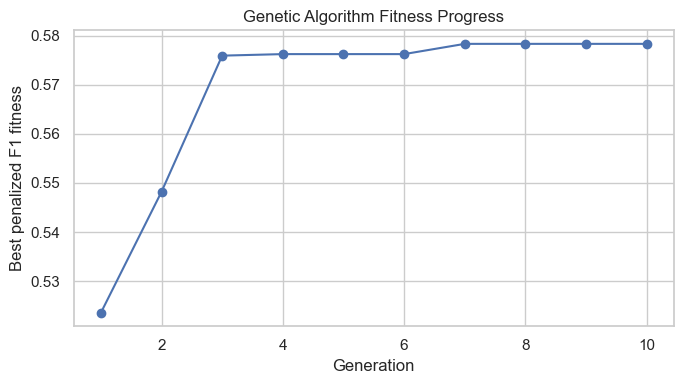

,metric,value
0,Selected features,"age, tenure, balance, products_number, active_..."
1,Selected-feature CV F1,0.584329
2,All-feature CV F1,0.562764
3,GA evaluations,59


In [12]:
ga_summary = pd.DataFrame({
    'metric': ['Selected features', 'Selected-feature CV F1', 'All-feature CV F1', 'GA evaluations'],
    'value': [', '.join(selected_features), selected_f1, all_features_f1, len(fitness_cache)]
})
ga_summary.to_csv(OUTPUT_DIR / 'ga_feature_selection_summary.csv', index=False)

plt.figure(figsize=(7, 4))
plt.plot(range(1, len(ga_history) + 1), ga_history, marker='o')
plt.title('Genetic Algorithm Fitness Progress')
plt.xlabel('Generation')
plt.ylabel('Best penalized F1 fitness')
save_and_show('ga_fitness_progress.png')

ga_summary

## 6. K-Medoids customer segmentation

To avoid binary compatibility issues from `scikit-learn-extra`, the notebook implements a small, dependency-free **alternate K-Medoids** algorithm using only NumPy and scikit-learn distance utilities.

The model is fitted on a fixed representative sample for speed, then all customers are assigned to the nearest fitted medoid. Candidate values of `k=2..6` are compared using:

- silhouette score (higher is better),
- total distance to medoids (lower is better), and
- minimum cluster share (to avoid tiny, unusable segments).

In [13]:
class KMedoidsAlternate:
    def __init__(self, n_clusters=3, random_state=42, max_iter=50):
        self.n_clusters = int(n_clusters)
        self.random_state = int(random_state)
        self.max_iter = int(max_iter)

    def _initialize_medoids(self, X):
        rng = np.random.default_rng(self.random_state)
        n_samples = len(X)
        medoids = [int(rng.integers(n_samples))]

        while len(medoids) < self.n_clusters:
            distances = pairwise_distances(X, X[medoids]).min(axis=1)
            distances[np.asarray(medoids)] = 0
            probabilities = distances ** 2

            if probabilities.sum() == 0:
                candidates = [i for i in range(n_samples) if i not in medoids]
                candidate = int(rng.choice(candidates))
            else:
                candidate = int(rng.choice(n_samples, p=probabilities / probabilities.sum()))

            if candidate not in medoids:
                medoids.append(candidate)

        return np.asarray(medoids, dtype=int)

    def fit(self, X):
        X = np.asarray(X, dtype=float)
        medoids = self._initialize_medoids(X)

        for iteration in range(self.max_iter):
            distances_to_medoids = pairwise_distances(X, X[medoids])
            labels = distances_to_medoids.argmin(axis=1)
            new_medoids = []

            for cluster_id in range(self.n_clusters):
                member_indices = np.where(labels == cluster_id)[0]

                if len(member_indices) == 0:
                    nearest_distance = distances_to_medoids.min(axis=1)
                    new_medoids.append(int(np.argmax(nearest_distance)))
                    continue

                local_distances = pairwise_distances(X[member_indices])
                best_local_index = int(np.argmin(local_distances.sum(axis=1)))
                new_medoids.append(int(member_indices[best_local_index]))

            new_medoids = np.asarray(new_medoids, dtype=int)
            if np.array_equal(np.sort(new_medoids), np.sort(medoids)):
                medoids = new_medoids
                break
            medoids = new_medoids

        self.medoid_indices_ = medoids
        self.cluster_centers_ = X[medoids]
        final_distances = pairwise_distances(X, self.cluster_centers_)
        self.labels_ = final_distances.argmin(axis=1)
        self.inertia_ = float(final_distances.min(axis=1).sum())
        self.n_iter_ = iteration + 1
        return self

    def fit_predict(self, X):
        return self.fit(X).labels_

    def predict(self, X):
        X = np.asarray(X, dtype=float)
        return pairwise_distances(X, self.cluster_centers_).argmin(axis=1)

X_selected = X_transformed[selected_transformed_columns].to_numpy()

CLUSTER_SAMPLE_SIZE = min(1500, len(X_selected))
rng = np.random.default_rng(SEED)
cluster_sample_indices = rng.choice(len(X_selected), size=CLUSTER_SAMPLE_SIZE, replace=False)
X_cluster_sample = X_selected[cluster_sample_indices]

kmedoids_results = []
for k in range(2, 7):
    model = KMedoidsAlternate(n_clusters=k, random_state=SEED, max_iter=40).fit(X_cluster_sample)
    labels = model.labels_
    score = silhouette_score(
        X_cluster_sample,
        labels,
        sample_size=min(1000, len(labels)),
        random_state=SEED
    )
    cluster_counts = np.bincount(labels, minlength=k)
    min_cluster_share = cluster_counts.min() / len(labels)
    kmedoids_results.append({
        'k': k,
        'total_distance': model.inertia_,
        'silhouette_score': score,
        'min_cluster_share': min_cluster_share
    })

kmedoids_results = pd.DataFrame(kmedoids_results)
kmedoids_results.to_csv(OUTPUT_DIR / 'kmedoids_k_selection.csv', index=False)
kmedoids_results

,k,total_distance,silhouette_score,min_cluster_share
0,2,2184.281448,0.115398,0.494667
1,3,2085.704423,0.116767,0.168667
2,4,1963.991510,0.124557,0.212667
3,5,1959.798576,0.101722,0.066667
4,6,1855.819538,0.117250,0.055333


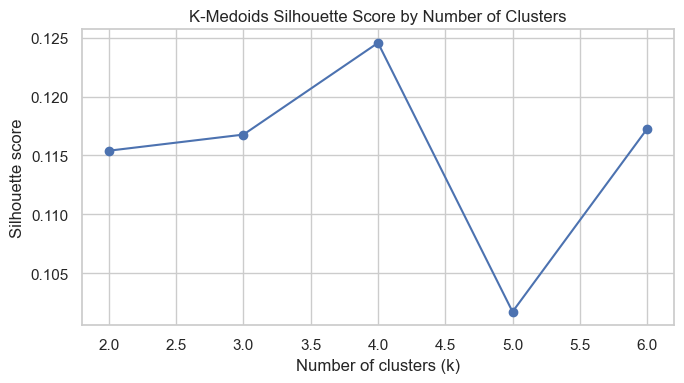

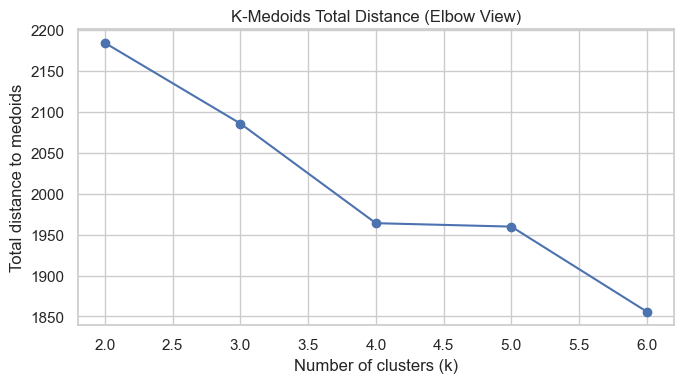

Selected k: 4
Silhouette score at selected k: 0.1246


In [14]:
valid_kmedoids = kmedoids_results[kmedoids_results['min_cluster_share'] >= 0.10]
if valid_kmedoids.empty:
    valid_kmedoids = kmedoids_results.copy()

best_k = int(valid_kmedoids.sort_values('silhouette_score', ascending=False).iloc[0]['k'])
best_kmedoids_silhouette = float(
    valid_kmedoids.loc[valid_kmedoids['k'] == best_k, 'silhouette_score'].iloc[0]
)

kmedoids_model = KMedoidsAlternate(
    n_clusters=best_k,
    random_state=SEED,
    max_iter=50
).fit(X_cluster_sample)

all_kmedoids_labels = kmedoids_model.predict(X_selected)

plt.figure(figsize=(7, 4))
plt.plot(kmedoids_results['k'], kmedoids_results['silhouette_score'], marker='o')
plt.title('K-Medoids Silhouette Score by Number of Clusters')
plt.xlabel('Number of clusters (k)')
plt.ylabel('Silhouette score')
save_and_show('kmedoids_silhouette_by_k.png')

plt.figure(figsize=(7, 4))
plt.plot(kmedoids_results['k'], kmedoids_results['total_distance'], marker='o')
plt.title('K-Medoids Total Distance (Elbow View)')
plt.xlabel('Number of clusters (k)')
plt.ylabel('Total distance to medoids')
save_and_show('kmedoids_elbow.png')

print(f'Selected k: {best_k}')
print(f'Silhouette score at selected k: {best_kmedoids_silhouette:.4f}')

## 7. Cluster profiles and business interpretation

In [15]:
segmented_df = df.copy()
segmented_df['kmedoids_cluster'] = all_kmedoids_labels

cluster_profiles = segmented_df.groupby('kmedoids_cluster').agg(
    customers=('customer_id', 'size'),
    churn_rate=('churn', 'mean'),
    avg_credit_score=('credit_score', 'mean'),
    avg_age=('age', 'mean'),
    avg_tenure=('tenure', 'mean'),
    avg_balance=('balance', 'mean'),
    avg_products=('products_number', 'mean'),
    credit_card_rate=('credit_card', 'mean'),
    active_rate=('active_member', 'mean'),
    avg_salary=('estimated_salary', 'mean')
).reset_index()

cluster_profiles['customer_share'] = cluster_profiles['customers'] / len(segmented_df)

risk_min = cluster_profiles['churn_rate'].min()
risk_max = cluster_profiles['churn_rate'].max()
if math.isclose(risk_min, risk_max):
    cluster_profiles['cluster_risk_index'] = 50.0
else:
    cluster_profiles['cluster_risk_index'] = (
        (cluster_profiles['churn_rate'] - risk_min) / (risk_max - risk_min) * 100
    )

overall_active = df['active_member'].mean()
overall_balance = df['balance'].mean()
overall_products = df['products_number'].mean()


def make_segment_name(row):
    risk = 'High-risk' if row['cluster_risk_index'] >= 67 else ('Medium-risk' if row['cluster_risk_index'] >= 33 else 'Low-risk')
    activity = 'Active' if row['active_rate'] >= overall_active else 'Low-activity'
    value = 'Higher-balance' if row['avg_balance'] >= overall_balance else 'Lower-balance'
    products = 'Multi-product' if row['avg_products'] >= overall_products else 'Low-product'
    return f'{risk} | {activity} | {value} | {products}'

cluster_profiles['segment_name'] = cluster_profiles.apply(make_segment_name, axis=1)
cluster_profiles.to_csv(OUTPUT_DIR / 'cluster_profiles.csv', index=False)

cluster_profiles[
    ['kmedoids_cluster', 'segment_name', 'customers', 'customer_share',
     'churn_rate', 'cluster_risk_index', 'avg_age', 'avg_balance',
     'avg_products', 'active_rate']
]

,kmedoids_cluster,segment_name,customers,customer_share,churn_rate,cluster_risk_index,avg_age,avg_balance,avg_products,active_rate
0,0,High-risk | Low-activity | Higher-balance | Lo...,2254,0.2254,0.321207,97.685883,40.688110,95602.052374,1.068323,0.328749
1,1,High-risk | Low-activity | Higher-balance | Mu...,2078,0.2078,0.327238,100.000000,49.611165,96409.570553,1.876805,0.367180
2,2,Low-risk | Active | Lower-balance | Multi-product,2897,0.2897,0.066621,0.000000,34.752848,21941.443117,2.008975,0.656541
3,3,Medium-risk | Active | Higher-balance | Low-pr...,2771,0.2771,0.158787,35.364834,33.827499,103019.999462,1.145435,0.629737


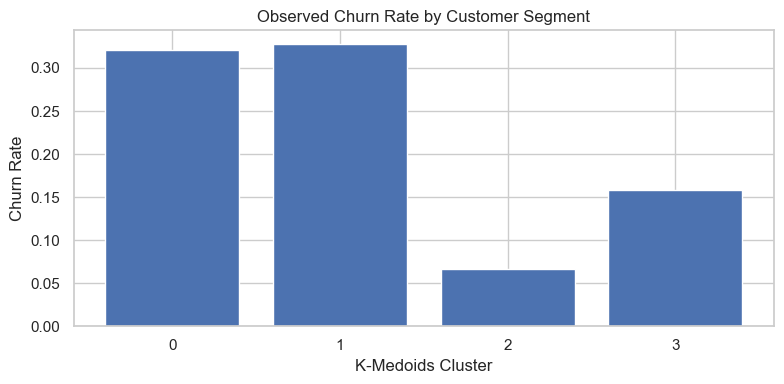

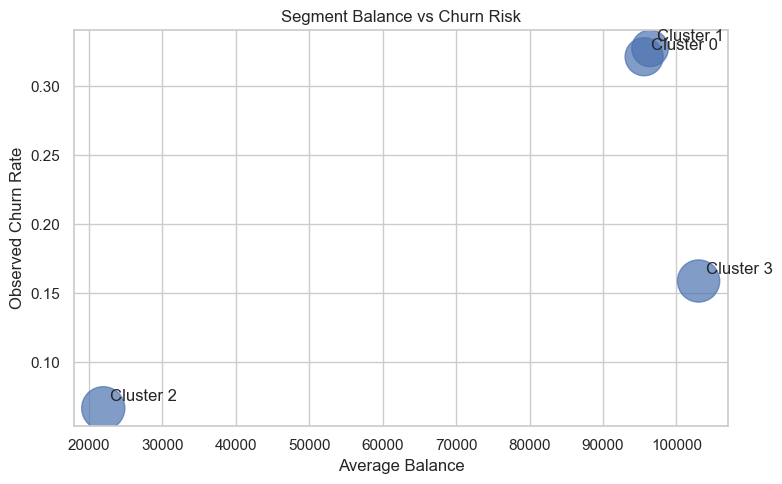

In [16]:
plt.figure(figsize=(8, 4))
plt.bar(cluster_profiles['kmedoids_cluster'].astype(str), cluster_profiles['churn_rate'])
plt.title('Observed Churn Rate by Customer Segment')
plt.xlabel('K-Medoids Cluster')
plt.ylabel('Churn Rate')
save_and_show('cluster_churn_rates.png')

plt.figure(figsize=(8, 5))
plt.scatter(
    cluster_profiles['avg_balance'],
    cluster_profiles['churn_rate'],
    s=cluster_profiles['customers'] / 3,
    alpha=0.7
)
for _, row in cluster_profiles.iterrows():
    plt.annotate(
        f"Cluster {int(row['kmedoids_cluster'])}",
        (row['avg_balance'], row['churn_rate']),
        xytext=(5, 5), textcoords='offset points'
    )
plt.title('Segment Balance vs Churn Risk')
plt.xlabel('Average Balance')
plt.ylabel('Observed Churn Rate')
save_and_show('segment_balance_vs_churn.png')

## 8. Hierarchical clustering benchmark

Hierarchical clustering is used as a benchmark rather than as a deployment model. `single`, `complete`, and `average` linkage are compared for `k=2..6`.

A high silhouette score can be misleading if it is created by isolating only one or two outliers. Therefore, this notebook also records the **minimum cluster share** and treats configurations with a cluster smaller than 5% of the sample as operationally unbalanced.

In [17]:
hierarchical_rows = []
for method in ['single', 'complete', 'average']:
    for k in range(2, 7):
        model = AgglomerativeClustering(n_clusters=k, linkage=method)
        labels = model.fit_predict(X_cluster_sample)
        score = silhouette_score(
            X_cluster_sample,
            labels,
            sample_size=min(1000, len(labels)),
            random_state=SEED
        )
        counts = np.bincount(labels, minlength=k)
        hierarchical_rows.append({
            'linkage': method,
            'k': k,
            'silhouette_score': score,
            'min_cluster_share': counts.min() / len(labels),
            'operationally_balanced': (counts.min() / len(labels)) >= 0.05
        })

hierarchical_results = pd.DataFrame(hierarchical_rows)
hierarchical_results.to_csv(OUTPUT_DIR / 'hierarchical_clustering_comparison.csv', index=False)

balanced_hierarchical = hierarchical_results[hierarchical_results['operationally_balanced']]
if balanced_hierarchical.empty:
    balanced_hierarchical = hierarchical_results.copy()

best_hierarchical = balanced_hierarchical.sort_values('silhouette_score', ascending=False).iloc[0]
best_hier_method = str(best_hierarchical['linkage'])
best_hier_k = int(best_hierarchical['k'])
best_hier_silhouette = float(best_hierarchical['silhouette_score'])

print('Best operationally balanced hierarchical configuration:')
print(f'  linkage = {best_hier_method}')
print(f'  k = {best_hier_k}')
print(f'  silhouette = {best_hier_silhouette:.4f}')

hierarchical_results.sort_values('silhouette_score', ascending=False).head(10)

Best operationally balanced hierarchical configuration:
  linkage = complete
  k = 2
  silhouette = 0.1990


,linkage,k,silhouette_score,min_cluster_share,operationally_balanced
0,single,2,0.481516,0.000667,False
10,average,2,0.481516,0.000667,False
1,single,3,0.275768,0.000667,False
11,average,3,0.254611,0.000667,False
2,single,4,0.237654,0.000667,False
3,single,5,0.217648,0.000667,False
4,single,6,0.217648,0.000667,False
12,average,4,0.200236,0.000667,False
5,complete,2,0.198960,0.218667,True
6,complete,3,0.150784,0.026667,False


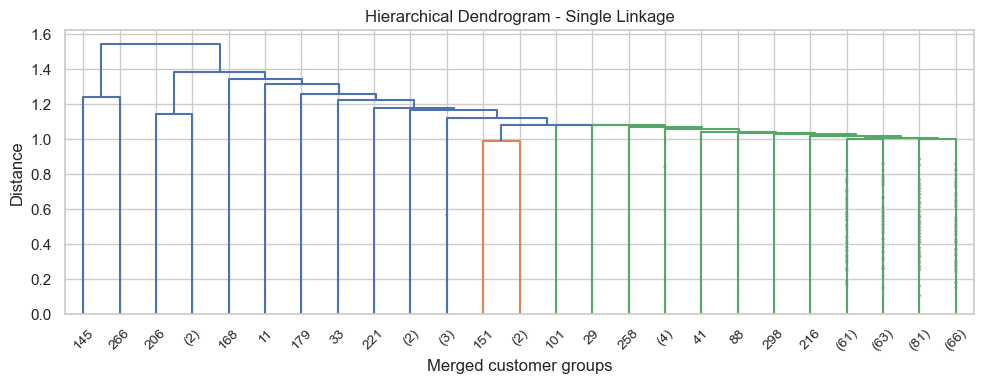

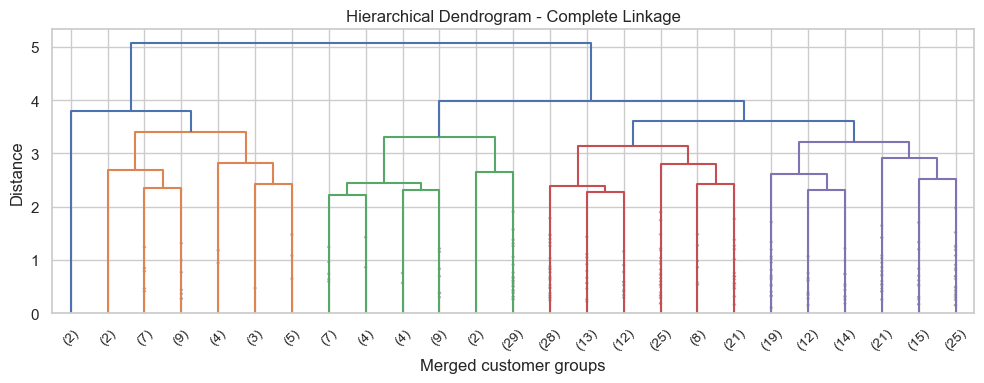

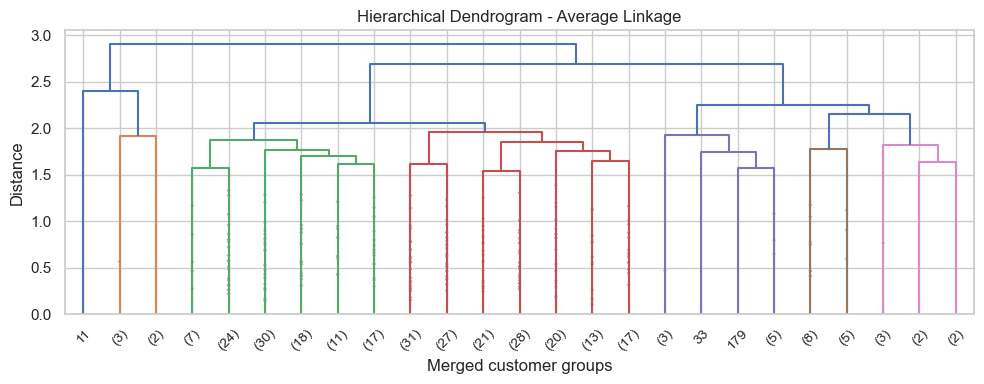

In [18]:
# Dendrograms are created on a smaller sample for readability.
HIER_DENDROGRAM_SAMPLE = min(300, len(X_cluster_sample))
rng = np.random.default_rng(SEED)
hier_indices = rng.choice(len(X_cluster_sample), size=HIER_DENDROGRAM_SAMPLE, replace=False)
X_hier = X_cluster_sample[hier_indices]

for method in ['single', 'complete', 'average']:
    plt.figure(figsize=(10, 4))
    Z = linkage(X_hier, method=method)
    dendrogram(Z, truncate_mode='lastp', p=25, show_contracted=True, leaf_rotation=45)
    plt.title(f'Hierarchical Dendrogram - {method.title()} Linkage')
    plt.xlabel('Merged customer groups')
    plt.ylabel('Distance')
    save_and_show(f'hierarchical_dendrogram_{method}.png')

### Model-selection interpretation
A clustering method is useful only when the statistical metric and the segment structure make business sense. The final portfolio output therefore keeps the balanced K-Medoids segmentation as the primary customer segmentation and reports hierarchical clustering as a benchmark.

In [19]:
model_comparison = pd.DataFrame([
    {
        'model': 'K-Medoids',
        'configuration': f'k={best_k}',
        'silhouette_score': best_kmedoids_silhouette,
        'use_in_project': 'Primary customer segmentation'
    },
    {
        'model': 'Hierarchical',
        'configuration': f'{best_hier_method}, k={best_hier_k}',
        'silhouette_score': best_hier_silhouette,
        'use_in_project': 'Benchmark / validation'
    }
])
model_comparison.to_csv(OUTPUT_DIR / 'clustering_model_comparison.csv', index=False)
model_comparison

,model,configuration,silhouette_score,use_in_project
0,K-Medoids,k=4,0.124557,Primary customer segmentation
1,Hierarchical,"complete, k=2",0.198960,Benchmark / validation


## 9. Explainable fuzzy retention-priority system

The fuzzy system is a **decision-support layer**, not a credit decision and not a causal churn model.

### Inputs
1. Customer balance
2. Activity status (0/1)
3. Relative cluster-risk index (0-100)

### Output
Retention priority score (0-100):
- Low priority: score < 40
- Moderate priority: 40-69.99
- High priority: 70+

The risk input uses a **relative index** derived from observed cluster churn rates. This makes the fuzzy “low / medium / high risk” sets meaningful even when absolute churn percentages are below 60%.

In [20]:
# Data-driven balance anchors from customers who hold a non-zero balance.
nonzero_balance = df.loc[df['balance'] > 0, 'balance']
balance_q25, balance_q50, balance_q75 = nonzero_balance.quantile([0.25, 0.50, 0.75]).tolist()
balance_max = float(max(250000, math.ceil(df['balance'].max() / 10000) * 10000))


def trimf(x, abc):
    a, b, c = abc
    x = np.asarray(x, dtype=float)
    y = np.zeros_like(x)
    if b != a:
        left = (x - a) / (b - a)
        y = np.maximum(y, np.minimum(left, 1))
    else:
        y = np.where(x == a, 1.0, y)
    if c != b:
        right = (c - x) / (c - b)
        y = np.minimum(y, np.maximum(right, 0))
    return np.clip(y, 0, 1)


def trapmf(x, abcd):
    a, b, c, d = abcd
    x = np.asarray(x, dtype=float)
    y = np.zeros_like(x)

    if b == a:
        y = np.where(x >= a, 1.0, y)
    else:
        y = np.maximum(y, np.clip((x - a) / (b - a), 0, 1))

    y = np.where((x >= b) & (x <= c), 1.0, y)

    if d == c:
        y = np.where(x <= d, y, 0.0)
    else:
        y = np.minimum(y, np.clip((d - x) / (d - c), 0, 1))

    return np.clip(y, 0, 1)


priority_universe = np.arange(0, 101, 1, dtype=float)
priority_memberships = {
    'low': trapmf(priority_universe, [0, 0, 20, 45]),
    'medium': trimf(priority_universe, [30, 55, 80]),
    'high': trapmf(priority_universe, [65, 82, 100, 100])
}


def balance_memberships(value):
    x = np.array([np.clip(float(value), 0, balance_max)])
    return {
        'low': float(trapmf(x, [0, 0, balance_q25, balance_q50])[0]),
        'medium': float(trimf(x, [balance_q25, balance_q50, balance_q75])[0]),
        'high': float(trapmf(x, [balance_q50, balance_q75, balance_max, balance_max])[0])
    }


def risk_memberships(value):
    x = np.array([np.clip(float(value), 0, 100)])
    return {
        'low': float(trapmf(x, [0, 0, 25, 50])[0]),
        'medium': float(trimf(x, [25, 50, 75])[0]),
        'high': float(trapmf(x, [50, 75, 100, 100])[0])
    }


def activity_memberships(value):
    value = float(np.clip(value, 0, 1))
    return {'inactive': 1.0 - value, 'active': value}

# Complete 3 x 2 x 3 rule base.
RULE_OUTPUTS = {
    ('low', 'active', 'low'): 'low',
    ('low', 'active', 'medium'): 'low',
    ('low', 'active', 'high'): 'medium',
    ('medium', 'active', 'low'): 'medium',
    ('medium', 'active', 'medium'): 'medium',
    ('medium', 'active', 'high'): 'high',
    ('high', 'active', 'low'): 'medium',
    ('high', 'active', 'medium'): 'high',
    ('high', 'active', 'high'): 'high',
    ('low', 'inactive', 'low'): 'medium',
    ('low', 'inactive', 'medium'): 'medium',
    ('low', 'inactive', 'high'): 'high',
    ('medium', 'inactive', 'low'): 'medium',
    ('medium', 'inactive', 'medium'): 'high',
    ('medium', 'inactive', 'high'): 'high',
    ('high', 'inactive', 'low'): 'high',
    ('high', 'inactive', 'medium'): 'high',
    ('high', 'inactive', 'high'): 'high'
}


def priority_label(score):
    if score < 40:
        return 'Low'
    if score < 70:
        return 'Moderate'
    return 'High'


def fuzzy_retention_priority(balance, active_member, cluster_risk_index, return_rules=False):
    balance_mu = balance_memberships(balance)
    active_mu = activity_memberships(active_member)
    risk_mu = risk_memberships(cluster_risk_index)

    aggregated = np.zeros_like(priority_universe)
    fired_rules = []

    for (risk_level, activity_level, balance_level), output_level in RULE_OUTPUTS.items():
        strength = min(
            risk_mu[risk_level],
            active_mu[activity_level],
            balance_mu[balance_level]
        )
        if strength <= 0:
            continue

        aggregated = np.maximum(
            aggregated,
            np.minimum(strength, priority_memberships[output_level])
        )
        fired_rules.append({
            'rule': f'IF risk={risk_level} AND activity={activity_level} AND balance={balance_level} THEN priority={output_level}',
            'strength': round(float(strength), 3)
        })

    if aggregated.sum() == 0:
        score = 50.0
    else:
        score = float(np.sum(priority_universe * aggregated) / np.sum(aggregated))

    fired_rules = sorted(fired_rules, key=lambda item: item['strength'], reverse=True)
    result = (score, priority_label(score))
    if return_rules:
        return score, priority_label(score), fired_rules
    return result

print('Balance membership anchors:')
print({'q25': balance_q25, 'median': balance_q50, 'q75': balance_q75, 'max_universe': balance_max})

Balance membership anchors:
{'q25': 100181.975, 'median': 119839.69, 'q75': 139512.29, 'max_universe': 260000.0}


## 10. End-to-end scoring for a new customer

In [21]:
cluster_lookup = cluster_profiles.set_index('kmedoids_cluster').to_dict('index')


def prepare_single_record(record_dict):
    frame = pd.DataFrame([record_dict])
    return transform_customers(frame[SOURCE_FEATURES] if set(SOURCE_FEATURES).issubset(frame.columns) else frame)


def final_customer_system(record_dict):
    transformed_record = prepare_single_record(record_dict)
    selected_record = transformed_record[selected_transformed_columns].to_numpy()
    cluster_id = int(kmedoids_model.predict(selected_record)[0])
    cluster_info = cluster_lookup[cluster_id]

    balance_value = float(record_dict.get('balance', numeric_fill_values['balance']))
    active_value = float(record_dict.get('active_member', numeric_fill_values['active_member']))

    score, label, fired_rules = fuzzy_retention_priority(
        balance=balance_value,
        active_member=active_value,
        cluster_risk_index=float(cluster_info['cluster_risk_index']),
        return_rules=True
    )

    return {
        'selected_source_features': selected_features,
        'kmedoids_cluster': cluster_id,
        'segment_name': cluster_info['segment_name'],
        'cluster_churn_rate': round(float(cluster_info['churn_rate']), 4),
        'cluster_risk_index': round(float(cluster_info['cluster_risk_index']), 2),
        'retention_priority_score': round(score, 2),
        'retention_priority_label': label,
        'top_fired_rules': fired_rules[:5]
    }

# Test 1: real dataset record.
real_record = df.drop(columns=['churn']).iloc[2].to_dict()
real_result = final_customer_system(real_record)
print('Real-record test result:')
display(real_result)

# Test 2: manually defined customer.
manual_record = {
    'customer_id': 15662100,
    'credit_score': 850,
    'country': 'Germany',
    'gender': 'Female',
    'age': 44,
    'tenure': 5,
    'balance': 128605.32,
    'products_number': 1,
    'credit_card': 0,
    'active_member': 1,
    'estimated_salary': 171096.20
}
manual_result = final_customer_system(manual_record)
print('\nManual-record test result:')
display(manual_result)

Real-record test result:


{'selected_source_features': ['age',
  'tenure',
  'balance',
  'products_number',
  'active_member',
  'estimated_salary'],
 'kmedoids_cluster': 1,
 'segment_name': 'High-risk | Low-activity | Higher-balance | Multi-product',
 'cluster_churn_rate': 0.3272,
 'cluster_risk_index': 100.0,
 'retention_priority_score': 86.56,
 'retention_priority_label': 'High',
 'top_fired_rules': [{'rule': 'IF risk=high AND activity=inactive AND balance=high THEN priority=high',
   'strength': 1.0}]}


Manual-record test result:


{'selected_source_features': ['age',
  'tenure',
  'balance',
  'products_number',
  'active_member',
  'estimated_salary'],
 'kmedoids_cluster': 3,
 'segment_name': 'Medium-risk | Active | Higher-balance | Low-product',
 'cluster_churn_rate': 0.1588,
 'cluster_risk_index': 35.36,
 'retention_priority_score': 46.79,
 'retention_priority_label': 'Moderate',
 'top_fired_rules': [{'rule': 'IF risk=low AND activity=active AND balance=medium THEN priority=low',
   'strength': 0.554},
  {'rule': 'IF risk=low AND activity=active AND balance=high THEN priority=medium',
   'strength': 0.446},
  {'rule': 'IF risk=medium AND activity=active AND balance=medium THEN priority=medium',
   'strength': 0.415},
  {'rule': 'IF risk=medium AND activity=active AND balance=high THEN priority=high',
   'strength': 0.415}]}

## 11. Score the full customer base and export portfolio outputs

In [22]:
cluster_profile_map = cluster_profiles.set_index('kmedoids_cluster')
priority_rows = []

for idx, row in segmented_df.iterrows():
    cluster_id = int(row['kmedoids_cluster'])
    cluster_info = cluster_profile_map.loc[cluster_id]
    score, label = fuzzy_retention_priority(
        balance=float(row['balance']),
        active_member=float(row['active_member']),
        cluster_risk_index=float(cluster_info['cluster_risk_index'])
    )
    priority_rows.append({
        'customer_id': row['customer_id'],
        'kmedoids_cluster': cluster_id,
        'segment_name': cluster_info['segment_name'],
        'cluster_churn_rate': cluster_info['churn_rate'],
        'cluster_risk_index': cluster_info['cluster_risk_index'],
        'retention_priority_score': score,
        'retention_priority_label': label,
        'actual_churn': int(row['churn'])
    })

customer_priorities = pd.DataFrame(priority_rows)
customer_priorities.to_csv(OUTPUT_DIR / 'customer_retention_priorities.csv', index=False)

priority_summary = customer_priorities.groupby('retention_priority_label').agg(
    customers=('customer_id', 'size'),
    average_priority_score=('retention_priority_score', 'mean'),
    observed_churn_rate=('actual_churn', 'mean')
).reindex(['Low', 'Moderate', 'High']).dropna().reset_index()
priority_summary['customer_share'] = priority_summary['customers'] / len(customer_priorities)
priority_summary.to_csv(OUTPUT_DIR / 'retention_priority_summary.csv', index=False)
priority_summary

,retention_priority_label,customers,average_priority_score,observed_churn_rate,customer_share
0,Low,2861,23.735439,0.096120,0.2861
1,Moderate,3230,57.472290,0.146440,0.3230
2,High,3909,85.627349,0.329752,0.3909


In [ ]:
plt.figure(figsize=(7, 4))
plt.bar(priority_summary['retention_priority_label'], priority_summary['customers'])
plt.title('Customers by Retention Priority')
plt.xlabel('Retention Priority')
plt.ylabel('Customers')
save_and_show('retention_priority_distribution.png')

plt.figure(figsize=(7, 4))
plt.bar(priority_summary['retention_priority_label'], priority_summary['observed_churn_rate'])
plt.title('Observed Churn Rate by Retention Priority')
plt.xlabel('Retention Priority')
plt.ylabel('Observed Churn Rate')
save_and_show('priority_vs_observed_churn.png')

## 12. Key findings and business recommendations

In [ ]:
highest_risk_cluster = cluster_profiles.sort_values('churn_rate', ascending=False).iloc[0]
lowest_risk_cluster = cluster_profiles.sort_values('churn_rate').iloc[0]

print('KEY FINDINGS')
print(f"1. Overall churn rate: {df['churn'].mean():.1%}.")
print(f"2. Inactive customer churn: {inactive_rate:.1%}; active customer churn: {active_rate:.1%}.")
print(f"3. Highest observed country churn: {country_high['country']} at {country_high['churn_rate']:.1%}.")
print(f"4. GA-selected churn-relevant features: {', '.join(selected_features)}.")
print(f"5. Primary K-Medoids segmentation uses {best_k} balanced clusters (silhouette={best_kmedoids_silhouette:.3f}).")
print(
    f"6. Highest-risk segment: Cluster {int(highest_risk_cluster['kmedoids_cluster'])} "
    f"with observed churn {highest_risk_cluster['churn_rate']:.1%}."
)
print(
    f"7. Lowest-risk segment: Cluster {int(lowest_risk_cluster['kmedoids_cluster'])} "
    f"with observed churn {lowest_risk_cluster['churn_rate']:.1%}."
)

print('\nBUSINESS RECOMMENDATIONS')
recommendations = [
    'Prioritize re-engagement campaigns for inactive customers, because activity status shows a large churn-rate gap.',
    'Use segment-level retention offers instead of a single campaign for the entire customer base.',
    'Review the highest-risk segment profile before allocating expensive retention incentives.',
    'Use the fuzzy priority score as a transparent queueing aid for retention outreach, not as a replacement for business judgment.',
    'A/B test retention interventions and track incremental churn reduction; descriptive churn patterns do not prove causality.'
]
for item in recommendations:
    print('-', item)

## 13. Conclusion

This individual project demonstrates an end-to-end analytical workflow: data auditing, EDA, feature engineering, churn-aware feature selection, explainable segmentation, model benchmarking, decision logic, and exportable business outputs.

The most important methodological choices are explicit:

- no customer rows are discarded simply because they are statistically extreme,
- categorical country data are one-hot encoded rather than assigned arbitrary ordinal distances,
- GA feature selection is clearly identified as supervised/churn-aware,
- clustering is evaluated using both silhouette score and cluster balance,
- fuzzy risk uses a relative cluster-risk index instead of unrealistic absolute thresholds,
- the final system reuses the exact fitted preprocessing steps for new customers.

The result is a portfolio-ready customer analytics project that can be explained clearly in an interview or to a client.